# Notebook 02: Transaction Dataset Preparation & Grounding
**Course:** 23CSE452 Business Analytics Capstone — Review 2  
**Objective:** Prepare and ground the high-velocity transaction dataset. Validate diurnal quick-commerce patterns and weekend demand uplifts against Redseer (2022) and Bain (2023).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tx_path = '../data/processed/synthetic/transactions/enhanced_synthetic_transactions.csv'
df_tx = pd.read_csv(tx_path)
print(f'Total Transaction Rows: {len(df_tx):,}')
print(f'Unique Synthetic Orders: {df_tx["synthetic_order_id"].nunique():,}')
print(f'Unique Customers: {df_tx["synthetic_customer_id"].nunique():,}')
df_tx.head(5)

Total Transaction Rows: 106,398
Unique Synthetic Orders: 34,700
Unique Customers: 4,994


,synthetic_order_id,synthetic_transaction_timestamp,synthetic_customer_id,synthetic_dark_store_id,synthetic_product_id,grounded_product_name,product_category,brand,pack_size,unit,...,discount_pct,discount_amount,line_total,order_value,payment_type,delivery_distance_km,source_product_id,source_price_observation_timestamp,data_origin,generation_rule_version
0,ORD_017803,2026-07-05 20:35:49,CUST_4293,DS_001,P011,Harvest Gold White Bread,Bakery,Harvest Gold,350.0,g,...,0.00,0.00,35.00,192.62,Credit Card,NaN,23779,2026-10-18 01:42:05,grounded_synthetic,v2.0_blinkit_grounded
1,ORD_033614,2026-09-25 23:01:05,CUST_2898,DS_001,P031,Potato (Aloo),Fruits & Vegetables,Generic / Unbranded,1.0,kg,...,15.00,3.60,20.40,281.83,UPI,2.3,199435,2026-10-18 01:42:05,grounded_synthetic,v2.0_blinkit_grounded
2,ORD_032323,2026-09-19 22:08:39,CUST_4760,DS_002,P029,Spring Onion (Hari Pyaz),Fruits & Vegetables,Freshbury,150.0,g,...,15.91,5.89,31.11,377.76,Cash on Delivery,1.7,421744,2026-10-18 01:42:05,grounded_synthetic,v2.0_blinkit_grounded
3,ORD_017309,2026-07-02 11:56:21,CUST_4405,DS_007,P049,SaveMore Toilet Cleaner Liquid,Household,SaveMore,500.0,ml,...,33.33,20.00,40.00,655.69,Credit Card,0.8,521559,2026-10-18 01:42:05,grounded_synthetic,v2.0_blinkit_grounded
4,ORD_012758,2026-06-08 08:17:15,CUST_3284,DS_006,P029,Spring Onion (Hari Pyaz),Fruits & Vegetables,Freshbury,150.0,g,...,15.91,11.77,62.23,690.97,Credit Card,0.8,421744,2026-10-18 01:42:05,grounded_synthetic,v2.0_blinkit_grounded


## 1. Diurnal Order Volume Validation (Hourly Distribution)

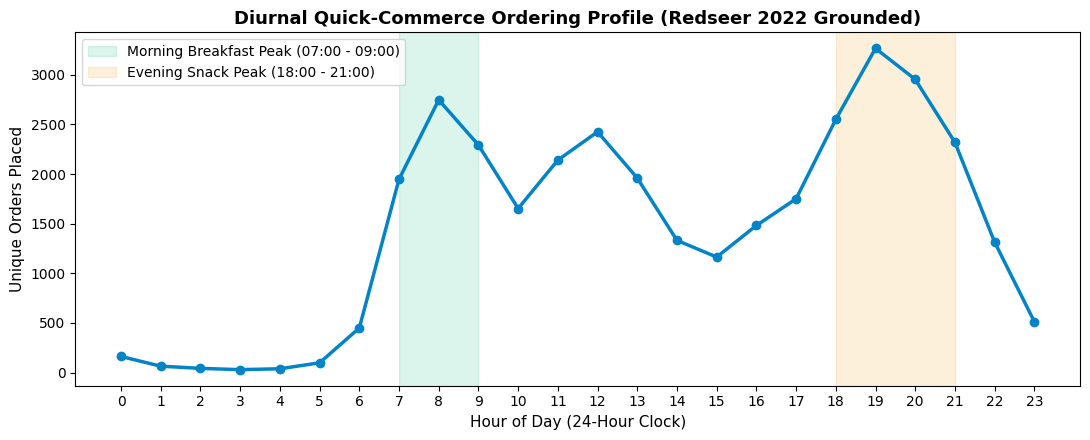

In [2]:
# Parse timestamp
df_tx['timestamp'] = pd.to_datetime(df_tx['synthetic_transaction_timestamp'])
df_tx['hour'] = df_tx['timestamp'].dt.hour
df_tx['day_name'] = df_tx['timestamp'].dt.day_name()
df_tx['date'] = df_tx['timestamp'].dt.date

hourly_orders = df_tx.groupby('hour')['synthetic_order_id'].nunique()

plt.figure(figsize=(11, 4.5))
plt.plot(hourly_orders.index, hourly_orders.values, marker='o', color='#0284c7', linewidth=2.5)
plt.axvspan(7, 9, color='#10b981', alpha=0.15, label='Morning Breakfast Peak (07:00 - 09:00)')
plt.axvspan(18, 21, color='#f59e0b', alpha=0.15, label='Evening Snack Peak (18:00 - 21:00)')
plt.title('Diurnal Quick-Commerce Ordering Profile (Redseer 2022 Grounded)', fontsize=13, fontweight='bold')
plt.xlabel('Hour of Day (24-Hour Clock)', fontsize=11)
plt.ylabel('Unique Orders Placed', fontsize=11)
plt.xticks(range(0, 24))
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 2. Daily Aggregated Demand Series Generation

In [3]:
daily_demand = df_tx.groupby('date')['quantity'].sum().reset_index()
daily_demand.columns = ['date', 'total_quantity']
daily_demand['date'] = pd.to_datetime(daily_demand['date'])
daily_demand = daily_demand.sort_values('date').reset_index(drop=True)

print(f'Total Operating Horizon: {len(daily_demand)} days')
print(f'Demand Range: Min = {daily_demand["total_quantity"].min()} units, Max = {daily_demand["total_quantity"].max()} units')
print(f'Mean Daily Units Demanded: {daily_demand["total_quantity"].mean():.1f}')
daily_demand.head(10)

Total Operating Horizon: 183 days
Demand Range: Min = 587 units, Max = 1176 units
Mean Daily Units Demanded: 837.3


,date,total_quantity
0,2026-04-01,748
1,2026-04-02,704
2,2026-04-03,851
3,2026-04-04,875
4,2026-04-05,849
5,2026-04-06,694
6,2026-04-07,781
7,2026-04-08,749
8,2026-04-09,778
9,2026-04-10,913


## 3. Train vs 30-Day Holdout Split Horizon

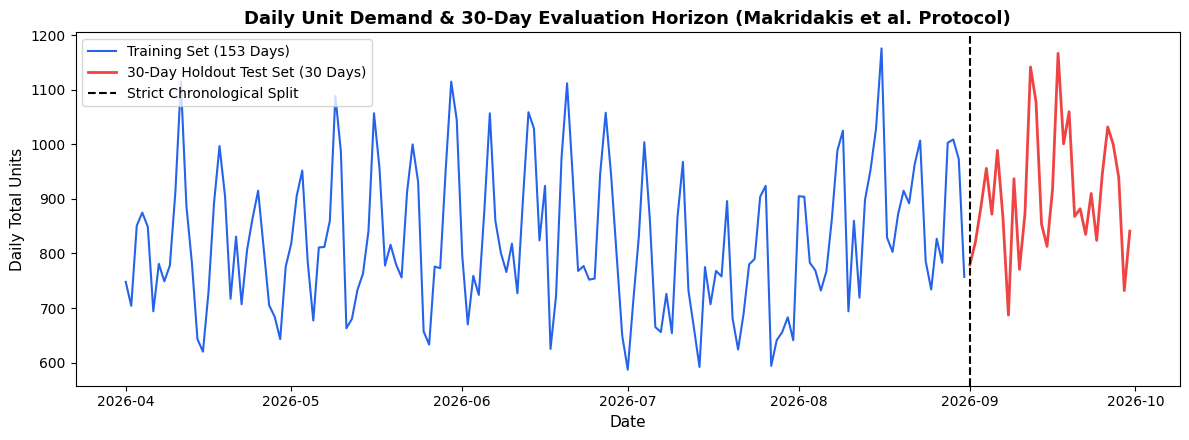

In [4]:
split_date = pd.to_datetime('2026-09-01')
train_set = daily_demand[daily_demand['date'] < split_date]
test_set = daily_demand[daily_demand['date'] >= split_date]

plt.figure(figsize=(12, 4.5))
plt.plot(train_set['date'], train_set['total_quantity'], label=f'Training Set ({len(train_set)} Days)', color='#2563eb', linewidth=1.5)
plt.plot(test_set['date'], test_set['total_quantity'], label=f'30-Day Holdout Test Set ({len(test_set)} Days)', color='#ef4444', linewidth=2)
plt.axvline(split_date, color='black', linestyle='--', linewidth=1.5, label='Strict Chronological Split')
plt.title('Daily Unit Demand & 30-Day Evaluation Horizon (Makridakis et al. Protocol)', fontsize=13, fontweight='bold')
plt.xlabel('Date', fontsize=11)
plt.ylabel('Daily Total Units', fontsize=11)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()